# Plantillas de clusters: reproducción de Canale (11/16) y O'Keeffe (0.6929)

**Dirección A** de la competencia: mejorar la cota inferior de la conectividad crítica $\mu_c$.

## Contexto: de dónde salen las cotas inferiores

Para probar $\mu_c \ge \mu$ alcanza con **un** grafo con conectividad $\mu$ que tenga una trampa: un
mínimo local estricto de la energía que no sea el estado sincronizado. Cuanto más denso es el grafo,
más difícil es que exista una trampa, así que la competencia consiste en construir grafos cada vez
más densos que sigan teniendo una.

| año | trabajo | cota | idea |
|---|---|---|---|
| 2006–2012 | Wiley–Strogatz–Girvan, Taylor | 0.6809 | twisted states en anillos $C_{n,k}$ |
| 2015–2021 | Canale–Monzón; Townsend–Stillman–Strogatz; Yoneda–Tatsukawa–Teramae | 0.6818 → 0.6838 | grafos circulantes optimizados |
| 2022 | Canale | 11/16 = 0.6875 | 8 clusters, primer grafo no circulante |
| oct. 2026 | O'Keeffe | 0.6929 | partir 3 de los 4 clusters de un estado degenerado |

Una aclaración sobre la normalización: la presentación usa $\mu = (\delta + 1)/n$ y los papers
$\mu = \delta/(n-1)$, con $\delta$ el grado mínimo. Para $n$ grande dan lo mismo y las cotas valen en
las dos.

## La idea común: estados de clusters y plantillas

Todas las construcciones récord tienen la misma forma: los osciladores se agrupan en **pocos
clusters**, y todos los de un cluster tienen la misma fase. Conviene describir el grafo a nivel de
clusters, con una **plantilla** $(x, \varphi, P)$:
- $x_a$: fracción de los $n$ osciladores que está en el cluster $a$ ($\sum_a x_a = 1$);
- $\varphi_a$: fase común del cluster $a$;
- $P_{ab} \in [0,1]$: fracción de los links posibles entre los clusters $a$ y $b$ que están presentes
  ($P_{aa}$ es la densidad dentro del cluster).

Una plantilla describe una familia de grafos grandes: el cluster $a$ tiene $x_a n$ vértices y cada uno
de ellos tiene $P_{ab} x_b n$ vecinos en el cluster $b$. Es exactamente la idea del "stackeo" de
`notes/idea.md`, generalizada a clusters de tamaños distintos y densidades intermedias.

## Cuándo una plantilla da una trampa

Para $n$ grande, todo se reduce a cuatro cantidades (O'Keeffe, sec. III):

| | fórmula | qué significa | condición |
|---|---|---|---|
| grado | $d_a = \sum_b P_{ab} x_b$ | grado de un vértice del cluster $a$, dividido por $n$ | $\mu(T) = \min_a d_a$ |
| equilibrio | $F_a = \sum_b P_{ab} x_b \sin(\varphi_a - \varphi_b)$ | suma de los tirones sobre un oscilador de $a$ | $= 0$ |
| splitting | $c_a = \sum_b P_{ab} x_b \cos(\varphi_a - \varphi_b)$ | fuerza que devuelve a su cluster a un oscilador que se separa | $> 0$ |
| modos de cluster | $L(y) = \sum_{a<b} x_a x_b P_{ab}\cos(\varphi_a-\varphi_b)(y_a-y_b)^2$ | cambio de energía si cada cluster rota rígido un ángulo $y_a$ | $> 0$ salvo $y \propto \mathbf 1$ |

**Notación.** $\mathbf 1 = (1, \dots, 1)$ es la dirección de la rotación global (sumar el mismo ángulo a todas las fases), que nunca cambia la energía. $\mathbf 1^\perp$ ("1 perpendicular") es su complemento ortogonal: los vectores $y$ con $\sum_a y_a = 0$. "$L \succ 0$ en $\mathbf 1^\perp$" quiere decir que $L$ es definida positiva en todas las direcciones salvo la rotación global, que es lo que se pide para un mínimo estricto.

¿Por qué alcanzan estas condiciones? El Hessiano del grafo grande tiene tres tipos de direcciones:
1. **los clusters se mueven en bloque:** la energía cambia según $L(y)$, salvo la rotación global
   $y \propto \mathbf 1$, que nunca cuesta nada;
2. **un oscilador se separa de su cluster:** sus compañeros lo traen de vuelta con fuerza
   $\propto c_a$;
3. **direcciones "oscilantes"** dentro de los anillos de la realización: se controlan eligiendo los
   links al azar (Lema 2 de O'Keeffe, ver sección 5).

Una plantilla que cumple las tres condiciones se llama **estricta**, y su blow-up da grafos con una
trampa. Al revés, agrupar por fase cualquier trampa da una plantilla, así que no se pierde nada:
**buscar trampas densas es buscar plantillas estrictas con $\mu$ alto**.

## Qué hay en este notebook

1. el lema del blow-up (la idea del grupo, verificada);
2. a 5. reproducción de C4, twisted states, Canale y S7, con un **certificado propio** de S7;
6. a 8. exploraciones propias: otros patrones de partición, el caso sin densidades intermedias y
   semillas.

El código está en `src/` (`plantillas.py` tiene una sola implementación de $d, F, c, L$ que sirve
para números comunes, alta precisión e intervalos) y los experimentos largos en `scripts/`.

**Colab.** Este notebook usa `src/` y `data/` del repo, que es privado. En Colab, la celda de abajo lo clona usando un token de GitHub guardado en los Secrets (ícono de la llave, nombre `GITHUB_TOKEN`, con "Notebook access" activado); en local no hace nada. Para traer cambios nuevos: `!git -C /content/investighaton-teo-optimizacion-2026 pull`.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
CARPETA_REPO = "/content/investighaton-teo-optimizacion-2026"

if EN_COLAB:
    if not os.path.exists(CARPETA_REPO):
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")
        !git clone -q https://{token}@github.com/Nicoyanz98/investighaton-teo-optimizacion-2026.git {CARPETA_REPO}
    %cd {CARPETA_REPO}/notebooks
    !pip install -q -r requirements.txt

In [2]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp

from src import s7
from src.busqueda import FamiliaParticiones, base_canale
from src.certificado import certificar, fases_newton, racionalizar
from src.experimentos import cargar_json, silenciar_avisos
from src.grafos import blowup_cartesiano, blowup_lexicografico, conectividad, grafo_circulante
from src.kuramoto import clasificar, simular, twisted_state
from src.plantillas import analizar, plantilla_c4, plantilla_canale, realizar
from src.twisted_lp import mejor_twisted

silenciar_avisos()
plt.rcParams["figure.dpi"] = 110

## 1. El lema del blow-up

Es la versión correcta de la idea del "stackeo" (`notes/idea.md`). En el **blow-up lexicográfico**
$G[K_m]$ cada vértice pasa a ser un clique de $m$ copias, todas en la misma fase, y cada copia se une
con **todas** las copias de los vecinos del vértice original:
- el grado pasa a $m \cdot \deg(v) + (m - 1)$ y $n$ pasa a $mn$, así que $\mu = (\delta+1)/n$ queda
  **igual**. Para eso está el "+1" en la definición de $\mu$: representa el clique propio;
- la trampa sobrevive: los resortes nuevos unen vértices en la misma fase, así que no tiran y solo
  agregan curvatura positiva.

En cambio, en el **producto cartesiano** $G \,\square\, K_m$ (las copias solo se unen con las copias del
mismo vértice), el grado crece en $m - 1$ pero $n$ crece en un factor $m$, así que $\mu$ **baja**.

Ejemplo: la trampa $q = 1$ de $C_{20,6}$.

In [3]:
n = 20
W = grafo_circulante(n, 6)
theta = twisted_state(n, 1)
print(f"{'m':>2} {'producto':>13} {'μ':>7} {'clasificación':>16} {'λ_2':>7}")
for m in [1, 2, 3, 4]:
    productos = {"cartesiano": blowup_cartesiano(W, m), "lexicográfico": blowup_lexicografico(W, m)}
    for nombre, M in productos.items():
        tipo, autovalores = clasificar(np.tile(theta, m), M)
        print(f"{m:>2} {nombre:>13} {conectividad(M):7.4f} {tipo:>16} {np.sort(autovalores)[1]:7.3f}")

 m      producto       μ    clasificación     λ_2
 1    cartesiano  0.6500  mínimo estricto   0.505
 1 lexicográfico  0.6500  mínimo estricto   0.505
 2    cartesiano  0.3500  mínimo estricto   0.505
 2 lexicográfico  0.6500  mínimo estricto   1.009
 3    cartesiano  0.2500  mínimo estricto   0.505
 3 lexicográfico  0.6500  mínimo estricto   1.514
 4    cartesiano  0.2000  mínimo estricto   0.505
 4 lexicográfico  0.6500  mínimo estricto   2.019


## 2. El estado de 4 clusters C4 ($\mu = 3/4$)

**De dónde sale.** Kassabov, Strogatz y Townsend (2021) probaron que $\mu_c \le 3/4$ y mostraron por
qué su método no podía bajar de ahí: existen grafos de conectividad cercana a $3/4$ con un estado de
4 clusters que está **justo en el borde** de la estabilidad ("razor's edge"). Lo llamamos C4.

**El estado.** Cuatro clusters iguales en $0, \pi/2, \pi, 3\pi/2$. Cada cluster está completo por
dentro y unido completamente a sus dos vecinos, pero **no** al opuesto:
- grado: el propio cluster más los dos vecinos, $3 \cdot \frac14 = \frac34$;
- equilibrio: los dos vecinos tiran igual y en sentidos opuestos;
- splitting: $c_a = 1/4 > 0$ (solo tiran los compañeros, porque los vecinos están a $90°$ y
  $\cos 90° = 0$);
- modos de cluster: **$L \equiv 0$**. Rotar clusters enteros no cuesta energía a segundo orden,
  porque los pares unidos tienen $\cos = 0$ y los opuestos no están unidos.

**Qué se sabe.** Con el Hessiano no alcanza para decidir si C4 es un mínimo. Lepsveridze y Zhang
(ago. 2026) mostraron que **no** lo es: separar dos clusters vecinos baja la energía a tercer orden.
Eso da $\mu_c < 3/4$ estrictamente. Además probaron que cerca de $3/4$ el **único** obstáculo posible
es este estado de 4 clusters.

**Por qué importa.** C4 tiene $\mu$ muy alto, pero es degenerado. O'Keeffe (sección 5) lo usa de
punto de partida: si una deformación chica lo vuelve estable, se pierde poco $\mu$.

In [4]:
T = plantilla_c4()
reporte = T.reporte()
for clave, valor in reporte.items():
    print(f"{clave:16s} {valor:+.3e}")
print("autovalores de L en 1^⊥ (sin la rotación global):", np.round(T.autovalores_clusters(), 14))

mu               +7.500e-01
max|F|           +0.000e+00
min c            +2.500e-01
min autovalor L  -1.961e-17
autovalores de L en 1^⊥ (sin la rotación global): [-0.  0.  0.]


## 3. Twisted states como plantilla: un LP

**De dónde sale.** Las primeras cotas inferiores usan los twisted states de los calentamientos. En el
anillo $C_{n,k}$ el último $k$ con trampa da $\mu \to 0.681$ (Wiley–Strogatz–Girvan, Taylor). Después
se buscó en grafos **circulantes** más generales, donde cada vértice se une con los de ciertas
distancias, no necesariamente $1, \dots, k$. Canale–Monzón (2015) llegaron a 0.6818 haciendo el
producto de un circulante con un grafo completo, que es un blow-up. Townsend–Stillman–Strogatz
(2020) llegaron a 0.6828 y Yoneda–Tatsukawa–Teramae (2021), a 0.6838, con el circulante óptimo,
encontrado por programación entera.

**Como plantilla.** $m$ clusters iguales en $\varphi_a = 2\pi q a/m$ (un twisted state de $q$
vueltas), con una densidad $p_j$ que depende solo de la distancia $j$ entre clusters. Por simetría,
el equilibrio se cumple solo, y $L$ es una matriz circulante cuyos autovalores son **lineales** en
las $p_j$. Maximizar el grado con $L \succ 0$ es entonces un **programa lineal (LP)**, que se resuelve
exacto.

Se excluye $q = m/4$, que es C4 (degenerado). Lo esperable es reencontrar el 0.6838 de Yoneda et al.
y, para $m$ grande, el 0.681 de los anillos.

mejor: m = 19, μ = 0.683876   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)
m = 120: μ = 0.681966   (límite de C_(n,k) con q = 1: ≈ 0.681)


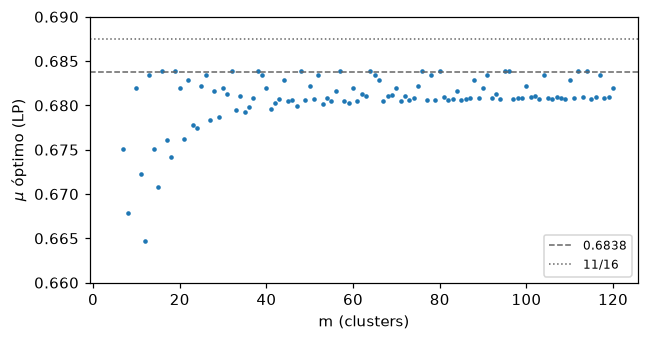

In [5]:
ms = np.arange(5, 121)
mejores = np.array([mejor_twisted(m) for m in ms])
i = mejores.argmax()
print(f"mejor: m = {ms[i]}, μ = {mejores[i]:.6f}   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)")
print(f"m = 120: μ = {mejores[-1]:.6f}   (límite de C_(n,k) con q = 1: ≈ 0.681)")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(ms, mejores, ".", ms=4)
referencias = [(0.6838, "0.6838", "--"), (11 / 16, "11/16", ":")]
for y, nombre, estilo in referencias:
    ax.axhline(y, ls=estilo, color="0.4", lw=1, label=nombre)
ax.set(xlabel="m (clusters)", ylabel=r"$\mu$ óptimo (LP)", ylim=(0.66, 0.69))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Canale (11/16)

**El paper** (Canale 2022, *From weighted to unweighted graphs in Synchronizing Graph Theory*) tiene
dos ideas.

**(1) De grafos con pesos a grafos simples: el $k$-spinning.** Es más fácil encontrar trampas en
grafos con **pesos** enteros en las aristas. Canale transforma un grafo con pesos en uno simple con
las mismas trampas: cada vértice pasa a ser un clique de $k$ copias, numeradas en $\mathbb Z_k$, y
una arista de peso $w$ une la copia $i$ con las copias $i, i+1, \dots, i+w-1$ del otro vértice. En el
lenguaje de plantillas, es un blow-up donde la densidad entre clusters es $w/k$. Así nacen las
**densidades intermedias**, que son la clave para pasar de 0.6838.

**(2) La construcción.** 8 clusters agrupados en 4 pares, un par por cuarto de vuelta. Los dos
miembros de cada par están en $\pi i/2 \pm \beta/2$. Se parece a C4 con cada cluster partido en
dos, pero la separación no es chica: $\beta \approx 26.6°$. Hay cuatro tipos de aristas, con pesos
$a, b, c, d$:

| tipo | diferencia de fase | quiénes | efecto |
|---|---|---|---|
| c | $\beta$ | los dos miembros de un par | estabiliza ($\cos > 0$) |
| a | $\alpha = \pi/2 - \beta$ | miembros cercanos de pares vecinos | estabiliza |
| b | $\pi/2$ | miembros "del mismo lado" de pares vecinos | neutro ($\cos = 0$); sus tirones se cancelan |
| d | $\alpha + 2\beta = \pi/2 + \beta$ | miembros lejanos de pares vecinos | **desestabiliza** ($\cos < 0$) |

- **Equilibrio:** $(a - d)\tan\alpha = c$, que fija el ángulo.
- **Estabilidad (Lema 1):** es estable si $c^2 > 2ad$.
- **Elección:** con $a = b = c = 1$, la estabilidad pide $d < 1/2$. Las aristas lejanas, las que
  desestabilizan, tienen que quedar **a la mitad de densidad**. Con $a = c = 1$ y $d = 1/2$ sale
  $\tan\alpha = 2$, o sea $\beta = \arctan(1/2) \approx 26.6°$.
- **Grado:** propio + $a$ + $2b$ + $c$ + $d$ $= (1 + 1 + 2 + 1 + \tfrac12)/8 = 5.5/8 = 11/16$, en
  el límite $d \to 1/2^-$.

Una aclaración: los conjuntos de aristas $E_t$ del paper tienen erratas (se superponen entre sí). Usamos
la geometría de su Fig. 2 y del Hessiano del Lema 1, que no son ambiguos. Abajo se ve que la
plantilla es estable exactamente cuando $d < 1/2$, como dice el Lema 1.

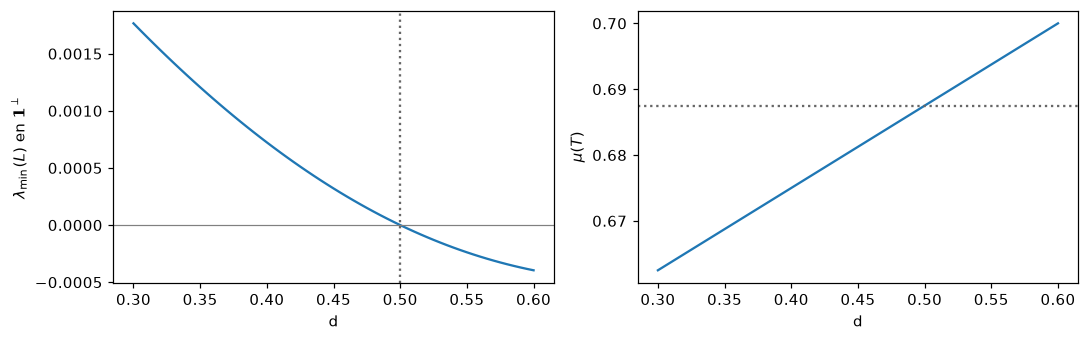

In [6]:
ds = np.linspace(0.3, 0.6, 61)
autovalores_min = []
mus = []
for d in ds:
    T = plantilla_canale(d=d)
    autovalores_min.append(T.autovalores_clusters().min())
    mus.append(T.mu())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(ds, autovalores_min)
ax[0].axhline(0, color="0.5", lw=0.8)
ax[0].axvline(0.5, ls=":", color="0.4")
ax[0].set(xlabel="d", ylabel=r"$\lambda_{\min}(L)$ en $\mathbf{1}^\perp$")
ax[1].plot(ds, mus)
ax[1].axhline(11 / 16, ls=":", color="0.4")
ax[1].set(xlabel="d", ylabel=r"$\mu(T)$")
plt.tight_layout()
plt.show()

**Grafos reales.** Canale toma $p_k = (k, k, k, \lceil k/2\rceil - 1)$ y hace el $k$-spinning: sale un
grafo regular con $n = 8k$ vértices y $\mu \to 11/16$ cuando $k \to \infty$. Nuestra función
`realizar` con `tipo="intervalo"` construye exactamente esos grafos. Chequeamos con el Hessiano del
grafo entero (que sea mínimo estricto) y con una simulación desde un estado perturbado (que vuelva).
Con $k$ chico, $\mu$ queda debajo de 11/16: el récord es un **límite**.

In [7]:
print(f"{'k':>3} {'n':>4} {'δ':>4} {'δ/(n−1)':>8} {'clasificación':>16} {'λ_2':>7}")
for k in [4, 8, 12, 16, 20]:
    d = int(np.ceil(k / 2)) - 1
    W, theta = realizar(plantilla_canale(d=d / k), k, rng=0, tipo="intervalo")
    tipo, autovalores = clasificar(theta, W)
    delta = W.sum(axis=1).min()
    print(f"{k:>3} {len(W):>4} {delta:>4.0f} {delta / (len(W) - 1):8.4f} {tipo:>16} {np.sort(autovalores)[1]:7.3f}")

W, theta = realizar(plantilla_canale(d=3 / 8), 8, rng=0, tipo="intervalo")
perturbacion = 0.05 * np.random.default_rng(1).standard_normal(len(theta))
sim = simular(theta + perturbacion, W, guardar=False)
desvio = np.angle(np.exp(1j * (sim["theta"] - theta)))
print(f"\nsimulación (k = 8) desde una perturbación de 0.05: vuelve al estado salvo rotación, "
      f"dispersión {np.ptp(desvio):.1e}")

  k    n    δ  δ/(n−1)    clasificación     λ_2
  4   32   20   0.6452  mínimo estricto   0.614
  8   64   42   0.6667  mínimo estricto   0.489
 12   96   64   0.6737  mínimo estricto   0.446
 16  128   86   0.6772  mínimo estricto   0.424
 20  160  108   0.6792  mínimo estricto   0.411



simulación (k = 8) desde una perturbación de 0.05: vuelve al estado salvo rotación, dispersión 7.0e-11


## 5. S7 de O'Keeffe (0.6929)

**El paper** (O'Keeffe, *Beyond 11/16: dense Kuramoto networks that resist synchrony*, oct. 2026)
sube la cota a $\mu_c \ge 0.6929077$. El autor cuenta que gran parte del trabajo la hicieron agentes
de IA (encontrar el estado, escribir las búsquedas y certificados, derivar la prueba), con él
eligiendo el problema y el estándar de evidencia. Sus scripts no son públicos; por eso los
reconstruimos.

**La idea en palabras.** Se parte de C4, que tiene $\mu = 3/4$ pero es degenerado: los clusters
vecinos están a $90°$ exactos y no se "sienten" a segundo orden. Para romper esa degeneración:
1. **Partir tres clusters vecinos** (A, B, C, cerca de $0$, $\pi/2$ y $\pi$) en dos mitades
   cada uno, separadas por ángulos **muy chicos**: $\pm h$, $\pm w h$ y $\pm h$, con $h$ del orden de
   $10^{-3}$ a $10^{-6}$. El cuarto cluster, W en $3\pi/2$, queda entero y hace de **ancla**. Son 7
   clusters, de ahí el nombre S7.
2. **Inclinar los links.** Al separar las mitades, algunos pares de mitades vecinas quedan un poco
   más cerca que $90°$ ($\cos > 0$, estabiliza) y otros un poco más lejos ($\cos < 0$,
   desestabiliza).
3. **Adelgazar los más inclinados.** Entre dos clusters partidos vecinos, el par de mitades más
   cercano y el más lejano (los links "cruzados") pasan a densidad $q \approx 0.65$, los dos por
   igual para que los tirones sigan equilibrados.
4. **El precio** es grado: con mitades de tamaño $a = 1/(7+q)$, la conectividad es
   $\mu = 1 - a(3 - q) = (4 + 2q)/(7 + q)$.

**Por qué $h \to 0$.** En las búsquedas del paper, el mejor $\mu$ mejora cuando $h$ achica (0.6906
con $h = 0.02$, 0.69272 con $h = 0.002$). En el límite $h \to 0$ la estabilidad se decide a orden $h^2$
y se reduce a una matriz de $3 \times 3$. Subir $q$ sube $\mu$, pero ablanda dos modos ("dipolos"):
rotar A contra C y rotar B contra W. El valor crítico $q^*$ es donde **los dos quedan exactamente
neutros**. Esa condición es un sistema de dos ecuaciones polinomiales, $f(q, w) = e(q, w) = 0$
(Apéndice A), que da
$$q^* \approx 0.6506, \qquad w^* \approx 1.398, \qquad \mu_0 = \frac{4 + 2q^*}{7 + q^*} = 0.6929077\ldots$$
$\mu_0$ es un número algebraico de grado 8: $q^*$ es raíz del polinomio (3) del paper.

**Cómo se convierte en un teorema.** En $q^*$ exacto los dipolos son neutros, así que el estado no es
estricto. Se toma $q = q^* - t$ con $t > 0$ chico, lo que da una brecha de orden $t$, y después $h$
chico **para ese $t$** (el orden importa). Eso da plantillas estrictas con $\mu \to \mu_0$ cuando
$t, h \to 0$, y por lo tanto $\mu_c \ge \mu_0$.

Primero reproducimos el modelo límite.

In [8]:
mp.mp.dps = 40
q, w, mu0 = s7.esquina()
print("q* =", mp.nstr(q, 20), "   w* =", mp.nstr(w, 20), "   μ0 =", mp.nstr(mu0, 20))
print("polinomio (3) en q*:", mp.nstr(s7.polinomio_3(q), 3))

q* = 0.65056916694479880261    w* = 1.3982781340204611796    μ0 = 0.69290770636958636365
polinomio (3) en q*: 1.47e-39


**Miembros finitos.** Para $(t, h)$ concretos, el paper da las densidades como
$$P = p + h\,p' + \Delta:$$
- $p$ es el patrón límite (Tabla II): 1 entre clusters vecinos y dentro de cada uno, $q$ en los
  cuatro pares cruzados, 0 entre opuestos;
- $p'$ es una corrección de primer orden, dada explícitamente en el Apéndice A. Hace que el
  equilibrio valga hasta orden $h$ y que las densidades que valían 1 queden por debajo de 1;
- $\Delta = O(h^2)$ es un ajuste final sobre un camino de 6 pares vecinos
  (Am–Bm–Cm–W–Cp–Bp–Ap) que hace el equilibrio **exacto**. Como $F$ es lineal en $P$, es un
  sistema lineal de $6 \times 6$.

Primero verificamos que $F(p + hp')$ escala como $h^2$, lo que confirma que leímos bien el $p'$ del
paper. Después miramos $\mu$ y el menor autovalor de $L$ fuera de la rotación para varios $(t, h)$.
Con $t < 0$, o sea $q > q^*$, tiene que fallar: es el control negativo.

In [9]:
for h in ["1e-2", "1e-3", "1e-4"]:
    S = s7.construir("1e-3", h, corregir=False)
    residuo = max(abs(v) for v in S["F_primer_orden"])
    print(f"h = {h}:  max|F(p + h p')| = {mp.nstr(residuo, 3)}")
print()
print(f"{'t':>7} {'h':>6} {'μ':>13} {'λ_min (M)':>10} {'estricta':>9}")
for t, h in [("0.01", "1e-3"), ("1e-3", "1e-4"), ("1e-5", "1e-6"), ("-0.01", "1e-4")]:
    S = s7.construir(t, h)
    r = analizar(S["x"], S["phi"], S["P"], mp)
    menor = min(r["autovalores L"])
    print(f"{t:>7} {h:>6} {mp.nstr(r['mu'], 11):>13} {mp.nstr(menor, 3):>10} {str(menor > 0):>9}")

h = 1e-2:  max|F(p + h p')| = 1.45e-5
h = 1e-3:  max|F(p + h p')| = 1.47e-7
h = 1e-4:  max|F(p + h p')| = 1.47e-9

      t      h             μ  λ_min (M)  estricta
   0.01   1e-3 0.69022172846    1.31e-8      True
   1e-3   1e-4 0.69263949191   1.32e-11      True
   1e-5   1e-6 0.69290502465   1.32e-17      True
  -0.01   1e-4 0.69451686914  -1.36e-10     False


**Certificado propio** (`src/certificado.py`, `scripts/certificar_s7.py`).

**Por qué hace falta.** El menor autovalor de $L$ es del orden de $10^{-18}$, más chico que el error de
redondeo de los números de punto flotante ($\sim 10^{-16}$). Un cálculo común no prueba nada. Se usa
**aritmética de intervalos**: cada número se reemplaza por un intervalo que seguro contiene el valor
verdadero, redondeando siempre hacia afuera. Si una desigualdad vale para todo el intervalo, vale
para el valor real.

**Los pasos** (mismo esquema que el Apéndice B del paper, con código escrito de cero):
1. redondear tamaños y densidades a fracciones exactas con denominador $D \approx 2 \cdot 10^{42}$;
2. refinar las fases por Newton en alta precisión (son irracionales, así que solo se conocen
   aproximadas);
3. **test de Krawczyk:** una versión de Newton con intervalos. Si manda una caja de fases (radio
   $\sim 10^{-54}$) estrictamente adentro de sí misma, hay **exactamente un** equilibrio verdadero en
   esa caja;
4. **Cholesky por intervalos:** una matriz simétrica es definida positiva si y solo si su
   factorización de Cholesky tiene pivotes positivos. Si funciona para la matriz de intervalos de
   $L$ (sin la fila de la rotación), vale para la $L$ verdadera, en el equilibrio verdadero;
5. $c_a > 0$ y fases distintas (no es el estado sincronizado) sobre toda la caja;
6. $\mu$ exacto como fracción.

**De la plantilla al grafo** (Lema 2 de O'Keeffe, que citamos y no reimplementamos para estos
tamaños). Cada cluster se vuelve un anillo $\mathbb Z_g$ y los links entre anillos se eligen con
"desplazamientos" al azar. Así cada vértice tiene exactamente el número de vecinos pedido (equilibrio
exacto), y las direcciones oscilantes quedan controladas con alta probabilidad. Para este miembro los
grafos son **gigantes** ($n \ge D^2 \sim 10^{84}$): se prueba que existen, pero nadie los escribe.

Con $(t, h) = (10^{-5}, 10^{-6})$ reproducimos la Proposición 1 de O'Keeffe,
$\mu^* = 0.6929050246493944\ldots$ La diferencia en el dígito 14 viene de cómo se redondean las fracciones.

In [10]:
S = s7.construir("1e-5", "1e-6", dps=120)
D = 2 * 10**42
xq, Pq = racionalizar(S["x"], S["P"], D)
phi = fases_newton(xq, Pq, S["phi"], dps=140)
resultado = certificar(xq, Pq, phi, radio=mp.mpf(10)**-54, dps=114)
print("\nO'Keeffe, Proposición 1: μ* = 0.6929050246493944…")

  krawczyk                     True
  min c (cota inf)             0.215744
  c>0                          True
  cholesky                     True
  min pivote (cota inf)        3.6094e-18
  min |sin(Δφ/2)| (cota inf)   1.0e-6
  distintas                    True
  ok                           True
  mu (exacto)                  0.6929050246493601  (denominador 282 bits)

O'Keeffe, Proposición 1: μ* = 0.6929050246493944…


## 6. Exploración: otros patrones de partición

S7 parte tres de los cuatro clusters de C4 en dos mitades. ¿Qué pasa con otros patrones, como partir
los cuatro, partir en tres piezas o partir solo dos?

**Cómo se busca.** Con tamaños y fases fijos, todas las condiciones de la plantilla son lineales en
las densidades $P$, salvo "$L \succ 0$", que es una desigualdad matricial lineal. Maximizar $\mu$ en
$P$ es entonces un **programa semidefinido (SDP)**: un problema convexo cuyo óptimo global se
encuentra de forma confiable (en el paper es el mismo paso interno). Afuera,
`scripts/explorar_particiones.py` mueve los tamaños y los desplazamientos de las piezas con
Nelder–Mead, que no es convexo, desde varios arranques.

Cada patrón `piezas = (k0, k1, k2, k3)` dice en cuántas piezas se parte cada cuarto de vuelta; S7 es
(2,2,2,1). Como la brecha de estabilidad es de orden $h^2$, el SDP trabaja con $L/h^2$; si no, el
margen numérico mata justo los estados buscados (O'Keeffe advierte esto en su sec. VI).

**Validación:** S7 con $h = 0.01$ da $0.69185$ y O'Keeffe reporta $0.6918$.

**Ojo:** estos números son evidencia numérica (SDP con tolerancias del solver), no certificados.

In [11]:
def mejores_por_patron(nombre):
    """{patrón: mejor μ} de un archivo de exploración de particiones."""
    mejores = {}
    for fila in cargar_json(nombre):
        mejores[tuple(fila["piezas"])] = fila["mejor_mu"]
    return mejores


aleatorio = mejores_por_patron("particiones_c4_h0.02_aleatorio.json")
estructurado = mejores_por_patron("particiones_c4_h0.02_estructurado.json")
print(f"h = 0.02          {'estructurado':>12} {'al azar':>9}")
for patron in sorted(estructurado, key=lambda p: -estructurado[p]):
    print(f"   {str(patron):14s} {estructurado[patron]:12.5f} {aleatorio[patron]:9.5f}")

h = 0.02          estructurado   al azar
   (3, 3, 3, 1)        0.69138   0.68638
   (2, 2, 2, 1)        0.69106   0.58707
   (3, 2, 2, 1)        0.68922   0.68137
   (2, 3, 2, 1)        0.68778   0.67612
   (2, 2, 3, 2)        0.68434   0.67807
   (3, 3, 3, 3)        0.68133   0.67345
   (2, 2, 2, 2)        0.68083   0.66611
   (2, 1, 2, 1)        0.66238   0.66430
   (3, 3, 1, 1)        0.65297   0.65848
   (2, 2, 1, 1)        0.64348   0.64011
   (3, 1, 1, 1)        0.60015   0.48450
   (2, 1, 1, 1)        0.58107   0.62744


**Arranques.** Con arranques al azar ni siquiera se reencuentra S7: (2,2,2,1) da 0.587. Es lo que
advierte O'Keeffe: las cuencas son angostas. Con arranques "estilo S7" (`arranque_estructurado`), los
patrones que parten el cluster ancla, o menos de tres clusters, quedan claramente debajo.
Solo (3,3,3,1) le gana a S7 con el mismo $h$. ¿Se mantiene la ventaja cuando $h \to 0$?

     h  S7 (2,2,2,1)  (3,3,3,1)  diferencia  O’Keeffe (S7)
  0.02       0.69106    0.69138    +0.00032         0.6906
  0.01       0.69190    0.69208    +0.00017         0.6918
 0.005       0.69243    0.69245    +0.00002         0.6924


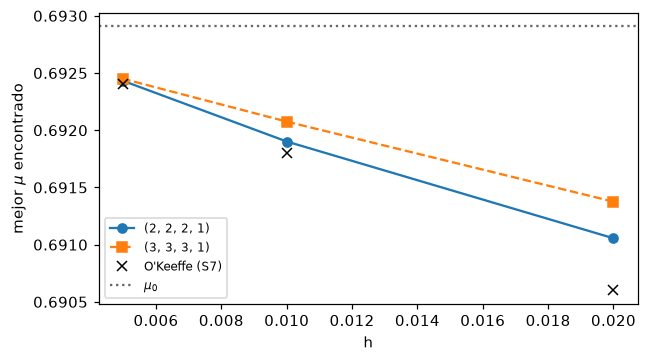

In [12]:
hs = [0.02, 0.01, 0.005]
archivos = {
    0.02: "particiones_c4_h0.02_estructurado.json",
    0.01: "particiones_c4_h0.01_estructurado_2221-3331.json",
    0.005: "particiones_c4_h0.005_estructurado_2221-3331.json",
}
okeeffe = {0.02: 0.6906, 0.01: 0.6918, 0.005: 0.6924}
s7_patron = (2, 2, 2, 1)
tres_piezas = (3, 3, 3, 1)
mejores = {s7_patron: [], tres_piezas: []}
for h in hs:
    por_patron = mejores_por_patron(archivos[h])
    for patron in mejores:
        mejores[patron].append(por_patron[patron])

print(f"{'h':>6} {'S7 (2,2,2,1)':>13} {'(3,3,3,1)':>10} {'diferencia':>11} {'O’Keeffe (S7)':>14}")
for i, h in enumerate(hs):
    a = mejores[s7_patron][i]
    b = mejores[tres_piezas][i]
    print(f"{h:>6} {a:13.5f} {b:10.5f} {b - a:+11.5f} {okeeffe[h]:14.4f}")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(hs, mejores[s7_patron], "o-", label=str(s7_patron))
ax.plot(hs, mejores[tres_piezas], "s--", label=str(tres_piezas))
ax.plot(list(okeeffe), list(okeeffe.values()), "x", color="k", label="O'Keeffe (S7)")
ax.axhline(float(mu0), ls=":", color="0.4", label=r"$\mu_0$")
ax.set(xlabel="h", ylabel=r"mejor $\mu$ encontrado")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

La diferencia baja más o menos linealmente con $h$ (+0.00032, +0.00018, +0.00002), así que en el límite
$h \to 0$ partir en 3 piezas **no** mejora $\mu_0$. Es consistente con la afirmación numérica de
O'Keeffe ("allowing more pieces per cluster did not raise it"). Es un resultado negativo, pero
documentado.

## 7. Caso 0/1: blow-ups completos (la idea original)

`scripts/explorar_01.py` recorre todos los grafos conexos $H$ con $k$ vértices (nauty), con
$P = A_H + I$ fija (cliques y bipartitos completos, sin densidades intermedias). Para cada uno
optimiza tamaños y fases con SLSQP desde 20 arranques.

In [13]:
for k in [5, 6, 7]:
    datos = cargar_json(f"blowups_01_k{k}.json")
    encontrados = datos["encontrados"]
    mejor = encontrados[0]["mu"] if encontrados else float("nan")
    print(f"k = {k}: {datos['cantidad_grafos']:4d} grafos, {datos['cantidad_prefiltro']:4d} pasan el prefiltro LP, "
          f"{len(encontrados):3d} con estado estricto no sync, mejor μ = {mejor:.4f}")

k = 5:   21 grafos,   13 pasan el prefiltro LP,   0 con estado estricto no sync, mejor μ = nan
k = 6:  112 grafos,   56 pasan el prefiltro LP,   3 con estado estricto no sync, mejor μ = 0.5998
k = 7:  853 grafos,  331 pasan el prefiltro LP,  32 con estado estricto no sync, mejor μ = 0.6162


Con grafos base chicos, los blow-ups completos no pasan de $\mu \approx 0.61$: hacen falta densidades
intermedias (las $d \to 1/2$ de Canale, las $q^* \approx 0.65$ de S7).

## 8. Semillas (vía E)

Una **semilla** es un estado de clusters con $\mu$ alto que está justo en el borde de la estabilidad
($L \succeq 0$ con modos neutros), como C4 o Canale en $d = 1/2$. Las construcciones récord son
semilla + deformación: S7 es C4 deformado. `scripts/barrer_semillas.py` busca semillas con el SDP sin
margen. Prueba una red de $\ell$ clusters equiespaciados y la unión de dos redes rotadas $\beta$; con
$\ell = 4$ es la geometría de Canale. Para dos redes se muestra el mejor $\mu$ de borde por $\ell$.
Más contexto en `notes/conclusiones_y_siguientes_pasos.md`, vía E.

`FamiliaParticiones` acepta cualquier base. Como chequeo, Canale sin partir (8 sectores de una pieza)
tiene que dar $11/16$.

In [14]:
semillas = cargar_json("semillas.json")
print("una red:")
for fila in semillas["una_red"]:
    print(f"   ℓ = {fila['l']:2d}   μ = {fila['mu']:.4f}   modos neutros = {fila['neutros']}")
print("dos redes (mejor por ℓ):")
vistos = set()
for fila in semillas["dos_redes"]:
    if fila["l"] in vistos:
        continue
    vistos.add(fila["l"])
    print(f"   ℓ = {fila['l']}   μ = {fila['mu']:.4f}   neutros = {fila['neutros']}   β = {fila['beta_grados']:.1f}°")

familia = FamiliaParticiones(base_canale(), [1] * 8, h=0.01)
print("\nCanale como base, sin partir: μ =", round(familia.mu(np.log(np.full(8, 1 / 8)), margen=0.0), 6))

una red:
   ℓ =  3   μ = 0.3333   modos neutros = 2
   ℓ =  4   μ = 0.7500   modos neutros = 3
   ℓ =  5   μ = 0.6584   modos neutros = 2
   ℓ =  6   μ = 0.6111   modos neutros = 2
   ℓ =  7   μ = 0.6751   modos neutros = 2
   ℓ =  8   μ = 0.6679   modos neutros = 2
   ℓ =  9   μ = 0.6512   modos neutros = 2
   ℓ = 10   μ = 0.6820   modos neutros = 2
   ℓ = 11   μ = 0.6722   modos neutros = 2
   ℓ = 12   μ = 0.6647   modos neutros = 2
dos redes (mejor por ℓ):
   ℓ = 4   μ = 0.6869   neutros = 2   β = 25.9°
   ℓ = 8   μ = 0.6839   neutros = 2   β = 20.9°
   ℓ = 5   μ = 0.6831   neutros = 2   β = 44.0°
   ℓ = 6   μ = 0.6628   neutros = 2   β = 30.7°
   ℓ = 3   μ = 0.6039   neutros = 2   β = 61.5°

Canale como base, sin partir: μ = 0.6875
